In [155]:
# importing desired libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

import warnings
warnings.simplefilter(action='ignore')

## EXPLORING DATA

In [156]:
# Importing 'train' data

df = pd.read_csv("C://Users//Lenovo//Downloads//archive (3)//train.csv")
df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income_>50K
0,67,Private,366425,Doctorate,16,Divorced,Exec-managerial,Not-in-family,White,Male,99999,0,60,United-States,1
1,17,Private,244602,12th,8,Never-married,Other-service,Own-child,White,Male,0,0,15,United-States,0
2,31,Private,174201,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,40,United-States,1
3,58,State-gov,110199,7th-8th,4,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,40,United-States,0
4,25,State-gov,149248,Some-college,10,Never-married,Other-service,Not-in-family,Black,Male,0,0,40,United-States,0


In [157]:
df.shape

(43957, 15)

In [158]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'educational-num',
       'marital-status', 'occupation', 'relationship', 'race', 'gender',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income_>50K'],
      dtype='object')

In [159]:
df.dtypes

age                 int64
workclass          object
fnlwgt              int64
education          object
educational-num     int64
marital-status     object
occupation         object
relationship       object
race               object
gender             object
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country     object
income_>50K         int64
dtype: object

In [160]:
for i in df.columns:
    print(i, len(df[i].unique()))
    print(df[i].unique())
    print()

age 74
[67 17 31 58 25 59 70 35 28 21 30 20 45 76 54 19 44 47 37 27 24 49 36 71
 62 64 53 34 42 26 43 23 56 40 63 50 29 52 33 38 66 46 32 68 41 80 73 39
 57 51 69 22 18 55 65 60 48 61 72 90 74 77 75 81 82 88 84 83 79 78 85 89
 87 86]

workclass 9
['Private' 'State-gov' 'Self-emp-not-inc' 'Federal-gov' 'Local-gov'
 'Self-emp-inc' nan 'Never-worked' 'Without-pay']

fnlwgt 26646
[366425 244602 174201 ...  68982 116562 375827]

education 16
['Doctorate' '12th' 'Bachelors' '7th-8th' 'Some-college' 'HS-grad' '9th'
 '10th' '11th' 'Masters' 'Preschool' '5th-6th' 'Prof-school' 'Assoc-voc'
 '1st-4th' 'Assoc-acdm']

educational-num 16
[16  8 13  4 10  9  5  6  7 14  1  3 15 11  2 12]

marital-status 7
['Divorced' 'Never-married' 'Married-civ-spouse' 'Widowed' 'Separated'
 'Married-spouse-absent' 'Married-AF-spouse']

occupation 15
['Exec-managerial' 'Other-service' 'Transport-moving' 'Adm-clerical'
 'Machine-op-inspct' 'Sales' 'Handlers-cleaners' 'Farming-fishing'
 'Protective-serv' 'Prof-special

In [161]:
df.describe()

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week,income_>50K
count,43957.000000,4.395700e+04,43957.000000,43957.000000,43957.000000,43957.000000,43957.000000
mean,38.617149,1.896730e+05,10.074118,1093.559797,88.246491,40.407694,0.239279
std,13.734401,1.058215e+05,2.575092,7570.536063,404.588410,12.400303,0.426648
min,17.000000,1.349200e+04,1.000000,0.000000,0.000000,1.000000,0.000000
25%,28.000000,1.174960e+05,9.000000,0.000000,0.000000,40.000000,0.000000
50%,37.000000,1.781000e+05,10.000000,0.000000,0.000000,40.000000,0.000000
75%,48.000000,2.376710e+05,12.000000,0.000000,0.000000,45.000000,0.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000,1.000000


In [162]:
# Removing duplicate records

df.drop_duplicates(inplace=True,ignore_index=True)
df.shape

(43912, 15)

- *Removed 40 duplicate records*

In [163]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43912 entries, 0 to 43911
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              43912 non-null  int64 
 1   workclass        41418 non-null  object
 2   fnlwgt           43912 non-null  int64 
 3   education        43912 non-null  object
 4   educational-num  43912 non-null  int64 
 5   marital-status   43912 non-null  object
 6   occupation       41410 non-null  object
 7   relationship     43912 non-null  object
 8   race             43912 non-null  object
 9   gender           43912 non-null  object
 10  capital-gain     43912 non-null  int64 
 11  capital-loss     43912 non-null  int64 
 12  hours-per-week   43912 non-null  int64 
 13  native-country   43149 non-null  object
 14  income_>50K      43912 non-null  int64 
dtypes: int64(7), object(8)
memory usage: 5.0+ MB


In [164]:
df.isnull().sum()

age                   0
workclass          2494
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2502
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      763
income_>50K           0
dtype: int64

## 
NULL HANDLING

***1. Deleting the null value records from the dataset as they are around 5% of number of total records in df***

In [165]:
updated_df1 = df
updated_df1 = updated_df1.dropna()
updated_df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40686 entries, 0 to 43911
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              40686 non-null  int64 
 1   workclass        40686 non-null  object
 2   fnlwgt           40686 non-null  int64 
 3   education        40686 non-null  object
 4   educational-num  40686 non-null  int64 
 5   marital-status   40686 non-null  object
 6   occupation       40686 non-null  object
 7   relationship     40686 non-null  object
 8   race             40686 non-null  object
 9   gender           40686 non-null  object
 10  capital-gain     40686 non-null  int64 
 11  capital-loss     40686 non-null  int64 
 12  hours-per-week   40686 non-null  int64 
 13  native-country   40686 non-null  object
 14  income_>50K      40686 non-null  int64 
dtypes: int64(7), object(8)
memory usage: 5.0+ MB


In [166]:
df.isnull().sum()

age                   0
workclass          2494
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2502
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      763
income_>50K           0
dtype: int64

***2. Filling out the null values with mean/median/Mode***

In [167]:
# All these are categorical columns, so let's get their mode

print("workclass mean:",df["workclass"].mode().iloc[0])
print("occupation mean:",df["occupation"].mode().iloc[0])
print("native-country mean:",df["native-country"].mode().iloc[0])

workclass mean: Private
occupation mean: Prof-specialty
native-country mean: United-States


In [168]:
null_col = ["workclass","occupation","native-country"]
updated_df2 = df

for i in null_col:
    updated_df2[i] = updated_df2[i].fillna(updated_df2[i].mode().iloc[0])
    
updated_df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43912 entries, 0 to 43911
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              43912 non-null  int64 
 1   workclass        43912 non-null  object
 2   fnlwgt           43912 non-null  int64 
 3   education        43912 non-null  object
 4   educational-num  43912 non-null  int64 
 5   marital-status   43912 non-null  object
 6   occupation       43912 non-null  object
 7   relationship     43912 non-null  object
 8   race             43912 non-null  object
 9   gender           43912 non-null  object
 10  capital-gain     43912 non-null  int64 
 11  capital-loss     43912 non-null  int64 
 12  hours-per-week   43912 non-null  int64 
 13  native-country   43912 non-null  object
 14  income_>50K      43912 non-null  int64 
dtypes: int64(7), object(8)
memory usage: 5.0+ MB


In [169]:
df.isnull().sum()

age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income_>50K        0
dtype: int64

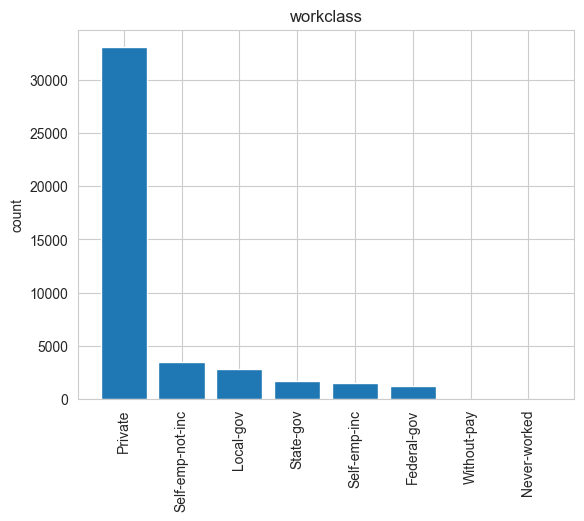

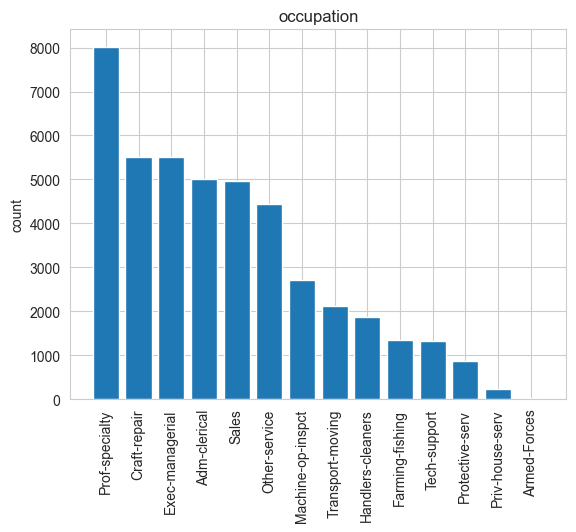

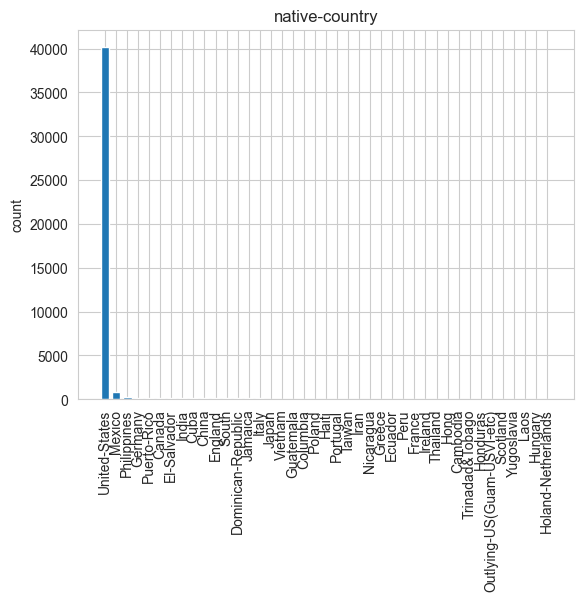

In [170]:
# # Data distribution in the columns containing null values

null_col = ["workclass","occupation","native-country"]

for col in null_col:
    plt.bar(x=df[col].value_counts().index, height=df[col].value_counts().values)
    plt.ylabel(df[col].value_counts().name)
    plt.title(col)
    plt.xticks(rotation=90) 
    plt.show()

**INSIGHTS:**
- Above 3 graphs shows that a partcular category in each is dominant in value count as compared to the others, so we can prefer filling null values in all these features using 'mode'.
- Also if we see the count of null values in the columns is around 5% or less than the overall records available in the dataframe, so we can also choose to drop these records.

***Dropping out the null records***

In [171]:
null_col = ["workclass","occupation","native-country"]

df.dropna(inplace=True) 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43912 entries, 0 to 43911
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              43912 non-null  int64 
 1   workclass        43912 non-null  object
 2   fnlwgt           43912 non-null  int64 
 3   education        43912 non-null  object
 4   educational-num  43912 non-null  int64 
 5   marital-status   43912 non-null  object
 6   occupation       43912 non-null  object
 7   relationship     43912 non-null  object
 8   race             43912 non-null  object
 9   gender           43912 non-null  object
 10  capital-gain     43912 non-null  int64 
 11  capital-loss     43912 non-null  int64 
 12  hours-per-week   43912 non-null  int64 
 13  native-country   43912 non-null  object
 14  income_>50K      43912 non-null  int64 
dtypes: int64(7), object(8)
memory usage: 5.0+ MB


In [172]:
# Separating out categorical and numerical data columns

nums = []
cat = []

for i in df.columns:
    if df[i].dtypes=='O':
        cat.append(i)
    else:
        nums.append(i)

## EDA

### Overall Income Distribution

income_>50K
0    76.058936
1    23.941064
Name: count, dtype: float64



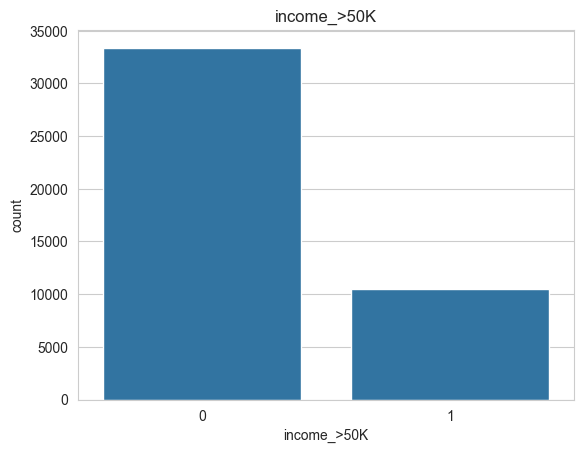

In [173]:
print(df["income_>50K"].value_counts()/len(df)*100)
print()

sns.countplot(data=df,x='income_>50K')
plt.title('income_>50K')
plt.show()

- Around 24% of the people have income above 50k, in overall dataset

### Countrywise Income:

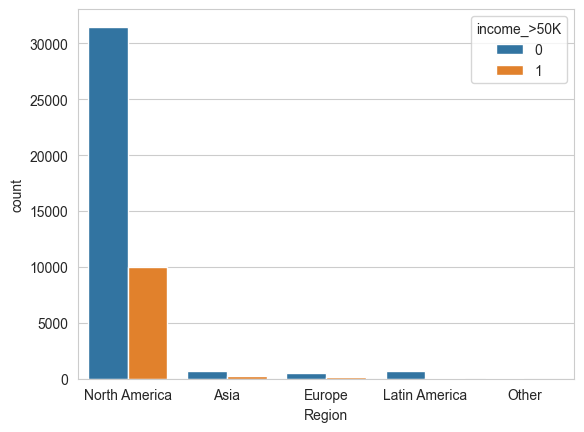

In [174]:
north_america = ['United-States', 'Mexico', 'Canada', 'Puerto-Rico', 'Cuba']
asia = ['Japan', 'South', 'Philippines', 'China', 'Vietnam', 'Thailand', 'India', 'Cambodia', 'Yugoslavia', 'Iran', 'Taiwan', 'Hong']
europe = ['Portugal', 'Italy', 'England', 'Germany', 'Poland', 'Greece', 'Ireland', 'Scotland', 'France', 'Hungary']
latin_america = ['Ecuador', 'Dominican-Republic', 'Jamaica', 'El-Salvador', 'Guatemala', 'Columbia', 'Haiti', 'Peru', 'Nicaragua', 'Trinadad&Tobago']
other = ['Outlying-US(Guam-USVI-etc)', 'Ireland', 'Canada', 'Laos', 'Honduras', 'Holand-Netherlands']

# Create a new column 'Region' based on the categories
df['Region'] = df['native-country'].apply(lambda x: 'North America' if x in north_america
                                   else 'Asia' if x in asia
                                   else 'Europe' if x in europe
                                   else 'Latin America' if x in latin_america
                                   else 'Other')

# df.drop(columns["Region"], inplace=True)

sns.countplot(data=df, x='Region', hue="income_>50K")
plt.show()

### Genderwise Income Distribution:

gender  income_>50K
Female  0              12955
        1               1590
Male    0              20444
        1               8923
Name: count, dtype: int64
-----
Male Income Distribution:

 income_>50K
0    69.615555
1    30.384445
Name: count, dtype: float64
-----
Female Income Distribution:

 income_>50K
0    89.068408
1    10.931592
Name: count, dtype: float64
-----


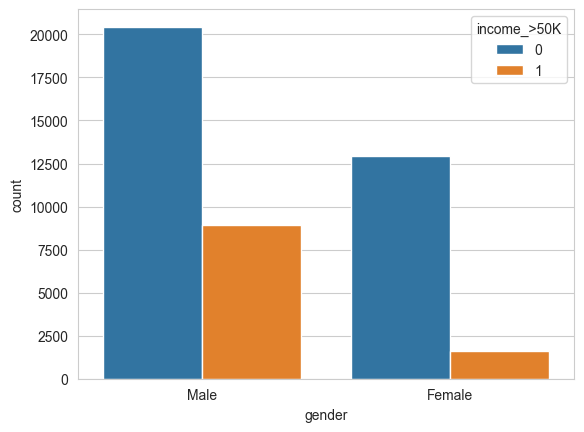

In [175]:
print(df.groupby(df["gender"])["income_>50K"].value_counts())
print('-----')

print("Male Income Distribution:\n\n", df[df["gender"]=='Male']["income_>50K"].value_counts()/len(df[df["gender"]=='Male'])*100)
print('-----')
print("Female Income Distribution:\n\n", df[df["gender"]=='Female']["income_>50K"].value_counts()/len(df[df["gender"]=='Female'])*100)
print('-----')

sns.countplot(data=df, x='gender', hue="income_>50K")
plt.show()

***Above distribution shows that the ratio of females having >50k income is 10%, lesser than that of male, which is around 30%

In [176]:
df["occupation"].unique()

array(['Exec-managerial', 'Other-service', 'Transport-moving',
       'Adm-clerical', 'Machine-op-inspct', 'Sales', 'Handlers-cleaners',
       'Farming-fishing', 'Protective-serv', 'Prof-specialty',
       'Craft-repair', 'Tech-support', 'Priv-house-serv', 'Armed-Forces'],
      dtype=object)

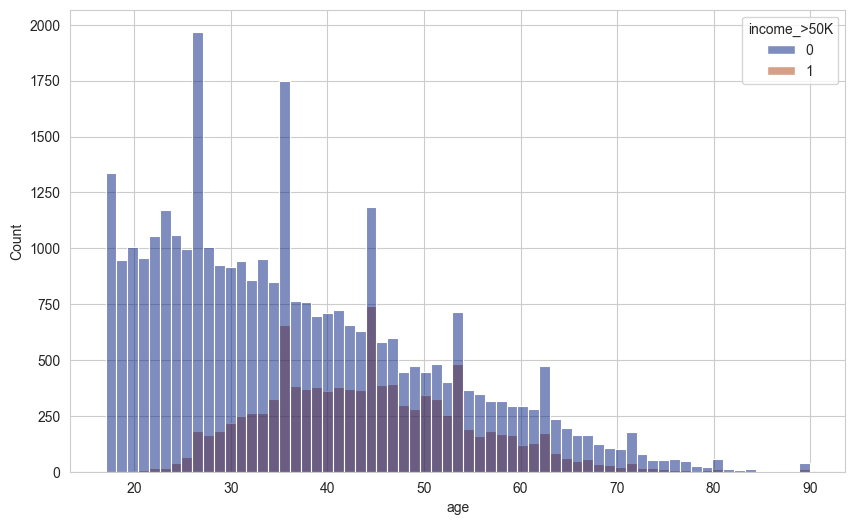

In [177]:
plt.figure(figsize=(10,6))
sns.histplot(x='age', hue='income_>50K', data=df, kde=False, palette='dark', )
plt.show()

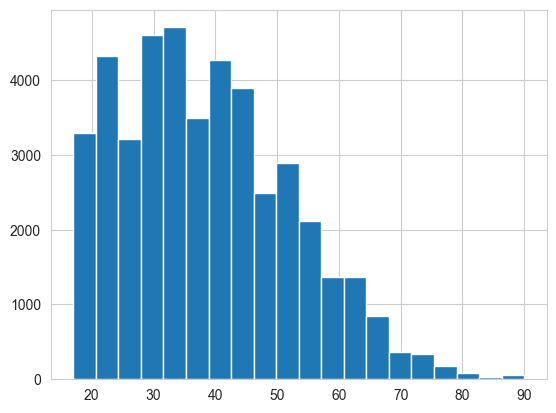

In [178]:
'''
matplotlib.pyplot.hist(x, bins=None, range=None, density=False, weights=None, cumulative=False,
bottom=None, histtype='bar', align='mid', orientation='vertical', rwidth=None, log=False, 
color=None, label=None, stacked=False, *, data=None, **kwargs)
'''

plt.hist(x='age',bins=20,data=df)
plt.show()

In [179]:
df['age'].value_counts().index

Index([33, 36, 31, 35, 23, 34, 28, 37, 30, 38, 32, 29, 27, 24, 41, 39, 22, 40,
       25, 26, 42, 20, 43, 47, 46, 21, 44, 45, 19, 51, 50, 18, 49, 48, 52, 53,
       54, 55, 17, 56, 57, 58, 59, 60, 61, 62, 64, 63, 65, 67, 66, 68, 69, 70,
       72, 71, 73, 74, 75, 76, 77, 90, 80, 81, 78, 79, 82, 84, 83, 88, 85, 89,
       87, 86],
      dtype='int64', name='age')

In [180]:
df['age'].value_counts()

age
33    1213
36    1212
31    1194
35    1192
23    1191
      ... 
88       6
85       4
89       2
87       2
86       1
Name: count, Length: 74, dtype: int64

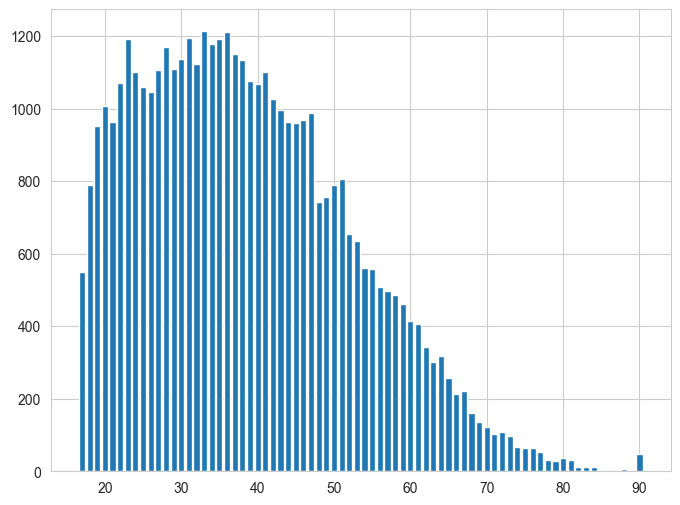

In [181]:
'''
matplotlib.pyplot.bar(x, height, width=0.8, bottom=None, *, align='center', data=None, **kwargs)
'''
age = df['age'].value_counts().index
count = df['age'].value_counts().values

plt.figure(figsize=(8,6))
plt.bar(x=age, height=count)
xlabel = 'age'
ylabel = 'count'
plt.show()

In [182]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'educational-num',
       'marital-status', 'occupation', 'relationship', 'race', 'gender',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income_>50K', 'Region'],
      dtype='object')

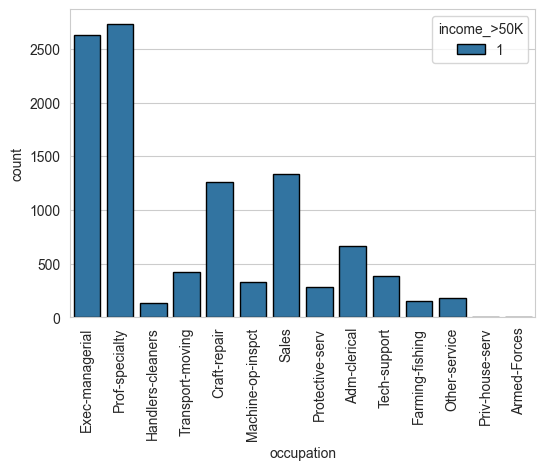

In [183]:
plt.figure(figsize=(6,4))
sns.countplot(x='occupation',hue='income_>50K',data=df[df["income_>50K"]==1],edgecolor='black')
plt.xticks(rotation=90)
plt.show()

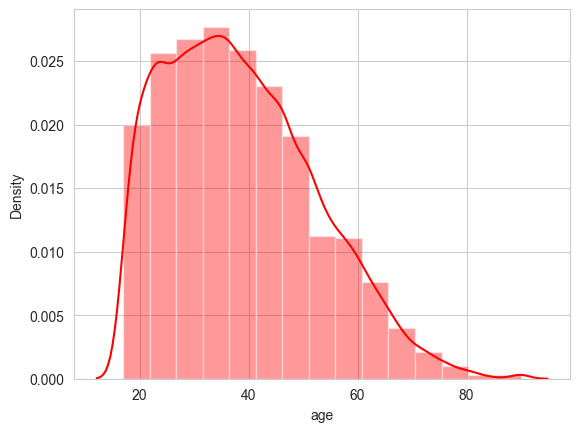

In [184]:
# set the background style of the plot
sns.set_style('whitegrid')
sns.distplot(df['age'], kde = True, color ='red', bins = 15)
plt.show()

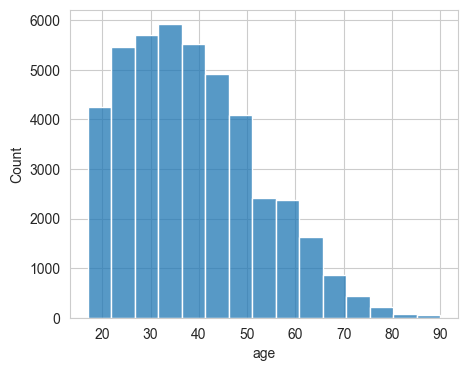

In [185]:
plt.figure(figsize=(5,4))
sns.histplot(df["age"],bins=15)
plt.show()

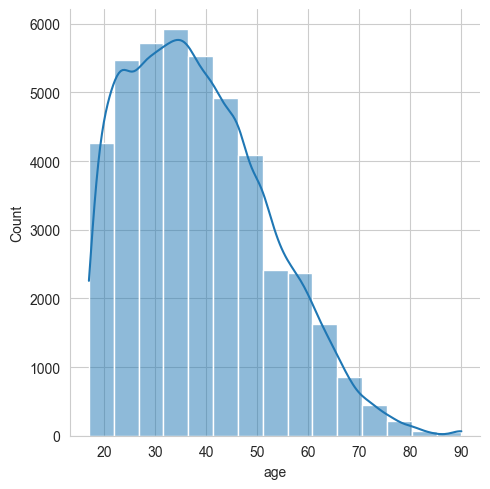

In [186]:
# Create Histogram with Density Curve Using Seaborn
sns.displot(df["age"], kde=True, bins=15)
plt.show()

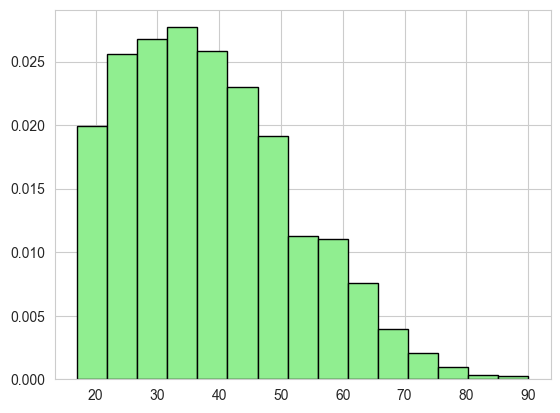

In [187]:
plt.hist(df["age"],color='lightgreen',ec="black",bins=15,density=True,)
plt.show()

<Axes: xlabel='age', ylabel='Density'>

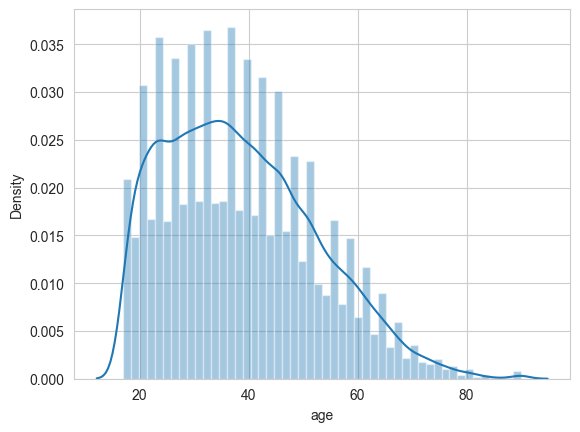

In [188]:
sns.distplot(df["age"],hist=True,kde=True)

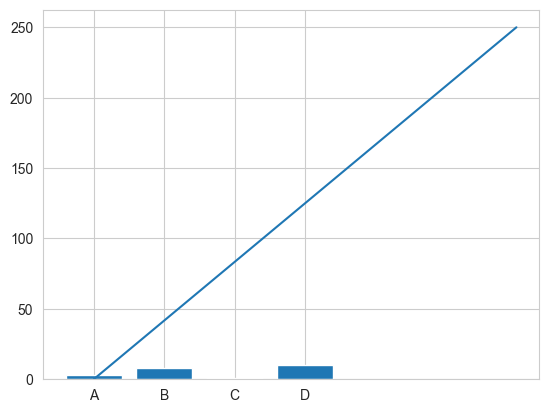

In [189]:
x = np.array(["A", "B", "C", "D"])
y = np.array([3, 8, 1, 10])
plt.bar(x=x, height=y)

plt.plot(np.array([0,6]), np.array([0,250]))

In [190]:
# Null values in workplace, occupation and native-country are around 5% of total record size, let's drop them

df = df.dropna()

In [191]:
nums = []
cat = []

for i in df.columns:
    if df[i].dtypes=='O':
        cat.append(i)
    else:
        nums.append(i)
    
print(nums)
print(cat)

['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'income_>50K']
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'native-country', 'Region']


In [192]:
df.corr(numeric_only=True)

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week,income_>50K
age,1.000000,-0.076670,0.034368,0.075799,0.056535,0.070633,0.230798
fnlwgt,-0.076670,1.000000,-0.040709,-0.003359,-0.006305,-0.011627,-0.006786
educational-num,0.034368,-0.040709,1.000000,0.126809,0.081006,0.145941,0.334185
capital-gain,0.075799,-0.003359,0.126809,1.000000,-0.031541,0.082727,0.223355
capital-loss,0.056535,-0.006305,0.081006,-0.031541,1.000000,0.055079,0.145234
hours-per-week,0.070633,-0.011627,0.145941,0.082727,0.055079,1.000000,0.227894
income_>50K,0.230798,-0.006786,0.334185,0.223355,0.145234,0.227894,1.000000


"\n'education-num', 'age', 'hours-per-week' has highest correlation with income\n"

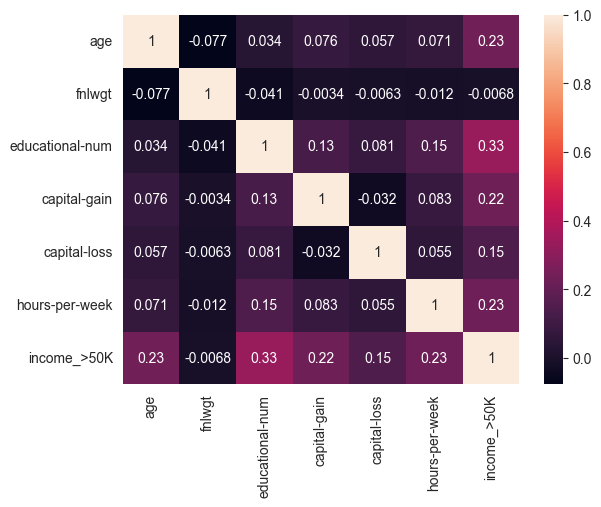

In [193]:
# Correlation between neumerical columns
sns.heatmap(df.corr(numeric_only=True),annot=True)

'''
'education-num', 'age', 'hours-per-week' has highest correlation with income
'''

#### Dealing with categorical columns

In [194]:
df["workclass"].value_counts()
# we can remove: Without-pay ,Never-worked 

workclass
Private             33042
Self-emp-not-inc     3463
Local-gov            2822
State-gov            1756
Self-emp-inc         1517
Federal-gov          1284
Without-pay            20
Never-worked            8
Name: count, dtype: int64

In [195]:
df["workclass"].value_counts()

workclass
Private             33042
Self-emp-not-inc     3463
Local-gov            2822
State-gov            1756
Self-emp-inc         1517
Federal-gov          1284
Without-pay            20
Never-worked            8
Name: count, dtype: int64

In [196]:
# df = df.drop(columns=["education"], axis=1)
# cat.remove("education")
df1 = pd.get_dummies(data=df, columns=cat, dtype=int)
df1

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week,income_>50K,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,...,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia,Region_Asia,Region_Europe,Region_Latin America,Region_North America,Region_Other
0,67,366425,16,99999,0,60,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0
1,17,244602,8,0,0,15,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
2,31,174201,13,0,0,40,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0
3,58,110199,4,0,0,40,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
4,25,149248,10,0,0,40,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43907,52,68982,13,0,0,50,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0
43908,19,116562,9,0,0,40,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
43909,30,197947,10,0,0,58,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
43910,46,97883,13,0,0,35,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0


In [197]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'educational-num',
       'marital-status', 'occupation', 'relationship', 'race', 'gender',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income_>50K', 'Region'],
      dtype='object')

#### test.csv

In [198]:
df_test = pd.read_csv("test.csv")
x_test = df_test

In [199]:
df_test.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'educational-num',
       'marital-status', 'occupation', 'relationship', 'race', 'gender',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country'],
      dtype='object')

In [200]:
nums = []
cat = []

for i in df_test.columns:
    if df_test[i].dtypes=='O':
        cat.append(i)
    else:
        nums.append(i)
    
print(nums)
print(cat)

['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'native-country']


In [201]:
df_test = df_test.drop(columns=["education"], axis=1)
cat.remove("education")
df2 = pd.get_dummies(data=df_test, columns=cat, dtype=int)
df2

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,...,native-country_Nicaragua,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-Rico,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States
0,39,327120,9,0,0,40,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
1,32,123253,12,0,0,42,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
2,47,232628,9,0,0,40,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
3,19,374262,8,0,0,20,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
4,46,311231,9,0,0,40,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
894,27,302406,14,0,0,55,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
895,17,218124,7,0,0,20,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
896,24,127139,10,0,0,40,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
897,35,132879,10,0,0,40,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1


In [202]:
for i in df1.columns:
    if i not in df2.columns and i!="income_>50K":
        df1 = df1.drop(columns=i, axis=1)

## MODEL BUILDING

In [203]:
x = df1.drop("income_>50K", axis=1)
y = df1["income_>50K"]

In [204]:
from sklearn.model_selection import train_test_split

# split data into train-test
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.20,random_state=10)

In [205]:
# scaling dataset

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_sc = scaler.fit_transform(x_train)
x_test_sc = scaler.transform(x_test)

print("Training input variables scaled:")
display(x_train_sc)
print()
print("Testing input variables scaled:")
display(x_test_sc)

Training input variables scaled:


array([[-1.426517  ,  0.28153884, -0.02952708, ..., -0.02614696,
        -0.02264199,  0.30806999],
       [-1.35382405,  0.89510835, -0.02952708, ..., -0.02614696,
        -0.02264199,  0.30806999],
       [ 0.82696422, -1.516934  , -0.41772202, ..., -0.02614696,
        -0.02264199,  0.30806999],
       ...,
       [ 0.39080656, -0.75418954, -0.41772202, ..., -0.02614696,
        -0.02264199,  0.30806999],
       [ 0.68157833,  0.1184584 ,  1.13505774, ..., -0.02614696,
        -0.02264199,  0.30806999],
       [ 0.89965716, -0.05088094, -0.41772202, ..., -0.02614696,
        -0.02264199,  0.30806999]])


Testing input variables scaled:


array([[ 2.13543718, -0.11633024, -1.58230684, ..., -0.02614696,
        -0.02264199,  0.30806999],
       [-0.77228052,  0.21376723, -0.02952708, ..., -0.02614696,
        -0.02264199,  0.30806999],
       [-0.19073698, -1.06744559, -0.41772202, ..., -0.02614696,
        -0.02264199,  0.30806999],
       ...,
       [-1.426517  ,  0.86647605, -0.02952708, ..., -0.02614696,
        -0.02264199,  0.30806999],
       [ 0.82696422, -0.141177  , -1.58230684, ..., -0.02614696,
        -0.02264199,  0.30806999],
       [ 0.10003479, -0.79281907,  1.91144761, ..., -0.02614696,
        -0.02264199,  0.30806999]])

In [206]:
# Create a logistic regression model

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
model = LogisticRegression()

In [207]:
# Fit the model to the training data
model.fit(x_train, y_train)

LogisticRegression()

In [208]:
logistic_accuracy = accuracy_score(y_test, model.predict(x_test))
logistic_accuracy

0.7930092223613799

In [209]:
# Make predictions on the testing data
y_pred = model.predict(x_test)

In [210]:
# Evaluate the model
from sklearn.metrics import accuracy_score
print('Accuracy:', accuracy_score(y_test, y_pred))
print()

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

Accuracy: 0.7930092223613799

              precision    recall  f1-score   support

           0       0.80      0.97      0.88      6674
           1       0.71      0.24      0.35      2109

    accuracy                           0.79      8783
   macro avg       0.75      0.60      0.62      8783
weighted avg       0.78      0.79      0.75      8783



## ridge

In [211]:
from sklearn.linear_model import RidgeClassifier
from sklearn.metrics import classification_report, accuracy_score

In [212]:
# Initialize and fit the RidgeClassifier model
ridge_model = RidgeClassifier(alpha=1.0, class_weight='balanced',random_state=42)
ridge_model.fit(x_train, y_train)

RidgeClassifier(class_weight='balanced', random_state=42)

In [213]:
# Predict and evaluate
ridge_predictions = ridge_model.predict(x_test)

In [214]:
# Calculate and print accuracy
ridge_accuracy = accuracy_score(y_test, ridge_predictions)
print(f"Accuracy: {ridge_accuracy:.2f}")

Accuracy: 0.78


In [215]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.97      0.88      6674
           1       0.71      0.24      0.35      2109

    accuracy                           0.79      8783
   macro avg       0.75      0.60      0.62      8783
weighted avg       0.78      0.79      0.75      8783



## naive bayes

In [216]:
from sklearn.naive_bayes import GaussianNB

In [217]:
# Initialize and fit the Naive Bayes model
nb_model = GaussianNB()
nb_model.fit(x_train_sc, y_train)

GaussianNB()

In [218]:
# Predict and evaluate
nb_predictions = nb_model.predict(x_test)
print(classification_report(y_test, nb_predictions))

              precision    recall  f1-score   support

           0       0.79      0.99      0.88      6674
           1       0.87      0.14      0.25      2109

    accuracy                           0.79      8783
   macro avg       0.83      0.57      0.56      8783
weighted avg       0.81      0.79      0.73      8783



In [219]:
naive_accuracy = accuracy_score(y_test, nb_predictions)
print(f"Accuracy: {naive_accuracy:.2f}")

Accuracy: 0.79


In [220]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.97      0.88      6674
           1       0.71      0.24      0.35      2109

    accuracy                           0.79      8783
   macro avg       0.75      0.60      0.62      8783
weighted avg       0.78      0.79      0.75      8783



### Comparing accuracies

In [221]:
# Compare accuracies
accuracies = {
    'Logistic Regression': logistic_accuracy,
    'ridge': ridge_accuracy,
    'naive' : naive_accuracy,
}

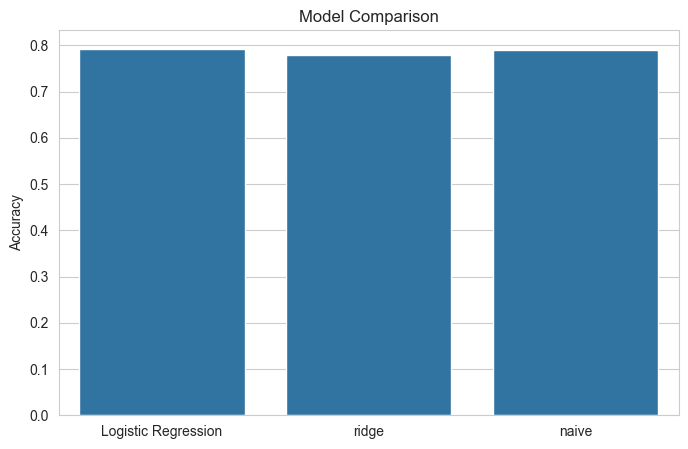

In [222]:
# Plot accuracies
plt.figure(figsize=(8, 5))
sns.barplot(x=list(accuracies.keys()), y=list(accuracies.values()))
plt.title('Model Comparison')
plt.ylabel('Accuracy')
plt.show()

In [223]:
# Select the best model
best_model_name = max(accuracies, key=accuracies.get)
print(f"The best model is: {best_model_name} with accuracy {accuracies[best_model_name]:.2f}")

# Use the best model for prediction
best_model = {'Logistic Regression': model,
              'naive bayes': nb_model,
              'ridge': ridge_model}[best_model_name]




The best model is: Logistic Regression with accuracy 0.79


In [224]:
print(x_train_sc.shape)
print(x_test.shape)

(35129, 75)
(8783, 75)


In [225]:
print(type(x_train_sc))


<class 'numpy.ndarray'>


In [226]:
# Check if x_train is a DataFrame
if isinstance(x_train, pd.DataFrame):
    x_train = x_train.to_numpy()  

# Check if x_test is a DataFrame
if isinstance(x_test, pd.DataFrame):
    x_test = x_test.to_numpy()  


x_train = x_train.reshape(x_train_sc.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)


In [229]:
input_data1 = x_test[1]  
input_data = scaler.transform([input_data1])  
prediction = best_model.predict(input_data)  
print("Prediction:", prediction[0])  


Prediction: 1
